# A. Import library

In [7]:
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.utils import make_grid

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# B. Konfigurasi

In [8]:
DATA_DIR   = "./orginal data"
IMG_SIZE   = 128
BATCH_SIZE = 32
N_EPOCHS   = 30
LR         = 0.001
SEED       = 42
USE_PRETRAINED = False

In [9]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(SEED)
 
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
print("Device:", device)

Device: mps


# C. Transform & Augmentasi

In [10]:
if USE_PRETRAINED:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
else:
    MEAN, STD = [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]

transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
transform_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# D. Import data & split

In [14]:
full_train = datasets.ImageFolder(DATA_DIR, transform=transform_train)
full_eval  = datasets.ImageFolder(DATA_DIR, transform=transform_eval)

class_names = full_train.classes

n_classes = len(class_names)
targets = np.array(full_train.targets)

print(f"Jumlah gambar: {len(full_train)} | Jumlah kelas: {n_classes}")
print("Kelas:", class_names)

Jumlah gambar: 1400 | Jumlah kelas: 5
Kelas: ['Chrysanthemum', 'Hibiscus', 'Marigold', 'Petuniya', 'Rose']


In [15]:
# Split stratified 70 / 15 / 15
idx_all = np.arange(len(targets))
idx_train, idx_tmp = train_test_split(
    idx_all, test_size=0.30, stratify=targets, random_state=SEED)
idx_val, idx_test = train_test_split(
    idx_tmp, test_size=0.50, stratify=targets[idx_tmp], random_state=SEED)

trainset = Subset(full_train, idx_train)
valset   = Subset(full_eval,  idx_val)
testset  = Subset(full_eval,  idx_test)

trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
valloader   = DataLoader(valset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
testloader  = DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(trainset)} | Val: {len(valset)} | Test: {len(testset)}")

Train: 980 | Val: 210 | Test: 210


# E. Visualisasi sample data

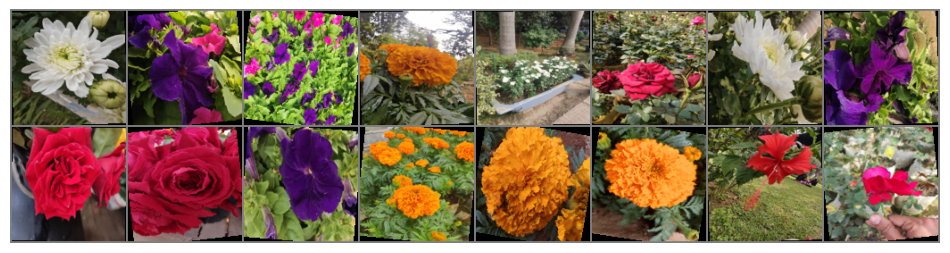

['Chrysanthemum', 'Petuniya', 'Petuniya', 'Marigold', 'Chrysanthemum', 'Rose', 'Chrysanthemum', 'Petuniya', 'Rose', 'Rose', 'Petuniya', 'Marigold', 'Marigold', 'Marigold', 'Hibiscus', 'Rose']


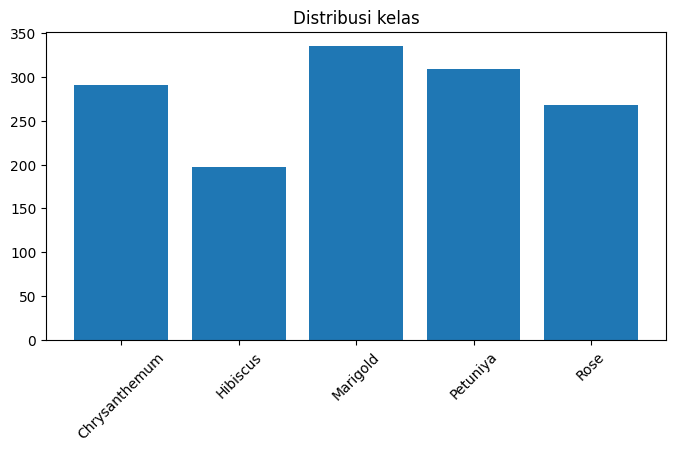

In [16]:
def imshow(img):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std  = torch.tensor(STD).view(3, 1, 1)
    img = img * std + mean
    plt.figure(figsize=(12, 6))
    plt.imshow(np.transpose(img.numpy().clip(0, 1), (1, 2, 0)))
    plt.axis("off"); plt.show()

images, labels = next(iter(trainloader))
imshow(make_grid(images[:16], nrow=8))
print([class_names[l] for l in labels[:16]])
plt.figure(figsize=(8, 4))
plt.bar(class_names, np.bincount(targets))
plt.xticks(rotation=45); plt.title("Distribusi kelas"); plt.show()


# F. Model CNN from scratch

In [17]:
class CNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1);   self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1);  self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1); self.bn3 = nn.BatchNorm2d(128)
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1);self.bn4 = nn.BatchNorm2d(256)
        self.pool  = nn.MaxPool2d(2, 2)
        self.gap   = nn.AdaptiveAvgPool2d((4, 4))
        self.fc1   = nn.Linear(256 * 4 * 4, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2   = nn.Linear(512, n_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = self.pool(F.relu(self.bn3(self.conv3(x))))
        x = self.pool(F.relu(self.bn4(self.conv4(x))))
        x = self.gap(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

# G. Inisialisasi model, loss, optimizer

In [18]:
net = build_pretrained(n_classes) if USE_PRETRAINED else CNN(n_classes)
net = net.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(filter(lambda p: p.requires_grad, net.parameters()), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", patience=3, factor=0.5)

print(net)
print("Trainable params:", sum(p.numel() for p in net.parameters() if p.requires_grad))

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (gap): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc1): Linear(in_features=4096, out_features=512, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=512, out_features=5, bias=True)
)
Trainable params: 2489605


# H. Training phase

In [19]:
def evaluate(model, loader):
    model.eval()
    correct, total, running_loss = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            running_loss += criterion(out, y).item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return running_loss / total, 100 * correct / total

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc, best_wts = 0.0, copy.deepcopy(net.state_dict())

In [20]:
for epoch in range(N_EPOCHS):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = net(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        total += y.size(0)

    tr_loss, tr_acc = running_loss / total, 100 * correct / total
    va_loss, va_acc = evaluate(net, valloader)
    scheduler.step(va_acc)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)

    if va_acc > best_acc:
        best_acc, best_wts = va_acc, copy.deepcopy(net.state_dict())

    print(f"Epoch {epoch+1:02d}/{N_EPOCHS} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.2f}% | "
          f"val loss {va_loss:.4f} acc {va_acc:.2f}%")

net.load_state_dict(best_wts)
print(f"Selesai. Best val acc: {best_acc:.2f}%")

Epoch 01/30 | train loss 1.0884 acc 69.80% | val loss 0.3413 acc 88.10%
Epoch 02/30 | train loss 0.3275 acc 89.29% | val loss 0.2125 acc 92.38%
Epoch 03/30 | train loss 0.2997 acc 88.88% | val loss 0.2077 acc 92.38%
Epoch 04/30 | train loss 0.2169 acc 91.73% | val loss 0.2643 acc 90.95%
Epoch 05/30 | train loss 0.2215 acc 93.88% | val loss 0.1204 acc 95.71%
Epoch 06/30 | train loss 0.1154 acc 96.33% | val loss 0.1790 acc 92.86%
Epoch 07/30 | train loss 0.1306 acc 95.51% | val loss 0.1170 acc 96.19%
Epoch 08/30 | train loss 0.1371 acc 96.12% | val loss 0.1887 acc 94.29%
Epoch 09/30 | train loss 0.1795 acc 93.98% | val loss 0.1113 acc 96.67%
Epoch 10/30 | train loss 0.1058 acc 96.53% | val loss 0.0880 acc 96.67%
Epoch 11/30 | train loss 0.0765 acc 97.86% | val loss 0.0838 acc 96.67%
Epoch 12/30 | train loss 0.0854 acc 96.73% | val loss 0.1864 acc 91.43%
Epoch 13/30 | train loss 0.0563 acc 98.37% | val loss 0.2192 acc 95.71%
Epoch 14/30 | train loss 0.0512 acc 98.37% | val loss 0.0702 acc

# I. Kurva training

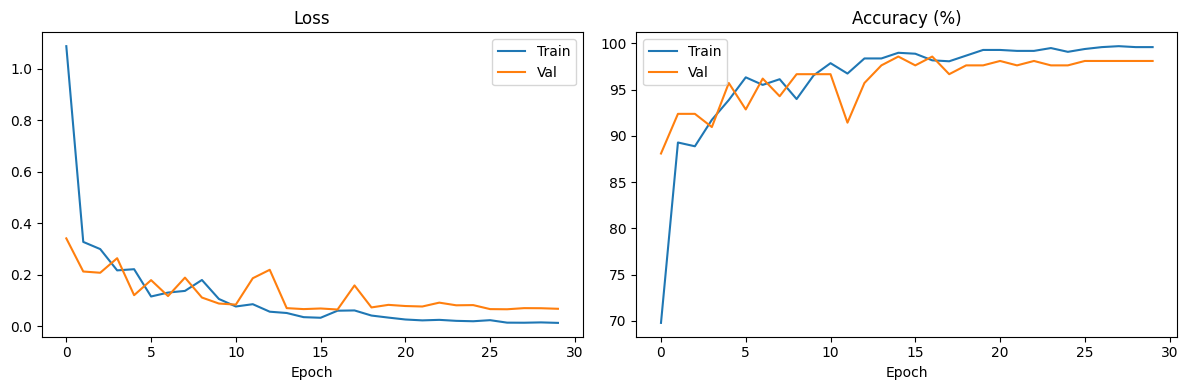

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="Train"); ax[0].plot(history["val_loss"], label="Val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="Train"); ax[1].plot(history["val_acc"], label="Val")
ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# J. Evaluation

               precision    recall  f1-score   support

Chrysanthemum     0.9565    1.0000    0.9778        44
     Hibiscus     0.9355    1.0000    0.9667        29
     Marigold     1.0000    0.9804    0.9901        51
     Petuniya     1.0000    1.0000    1.0000        46
         Rose     1.0000    0.9250    0.9610        40

     accuracy                         0.9810       210
    macro avg     0.9784    0.9811    0.9791       210
 weighted avg     0.9820    0.9810    0.9809       210



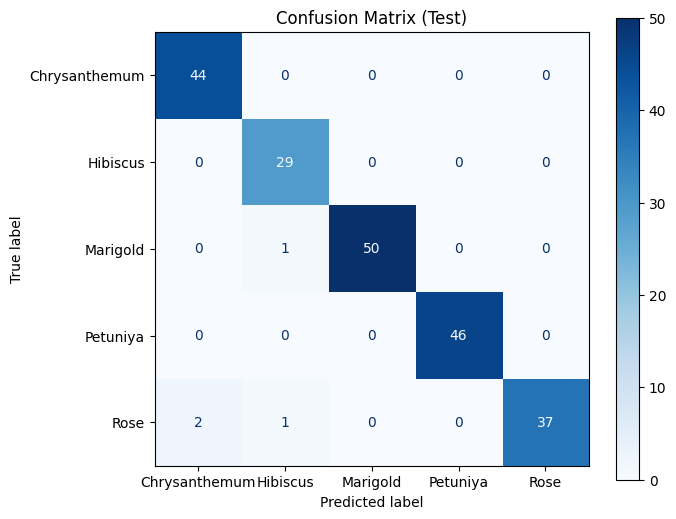

In [22]:
net.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in testloader:
        out = net(x.to(device))
        y_pred += out.argmax(1).cpu().tolist()
        y_true += y.tolist()

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=class_names, cmap="Blues", ax=ax)
ax.set_title("Confusion Matrix (Test)")
plt.show()

In [23]:
torch.save({"model_state": net.state_dict(), "classes": class_names}, "best_cnn.pth")
print("Model tersimpan: best_cnn.pth")

Model tersimpan: best_cnn.pth


In [24]:
import os

for class_name in full_train.classes:
    folder = os.path.join(DATA_DIR, class_name)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    original = [f for f in files if not f.startswith("aug_")]
    augmented = [f for f in files if f.startswith("aug_")]

    print(
        class_name,
        "| Original:", len(original),
        "| Augmented:", len(augmented)
    )

Chrysanthemum | Original: 291 | Augmented: 0
Hibiscus | Original: 197 | Augmented: 0
Marigold | Original: 335 | Augmented: 0
Petuniya | Original: 309 | Augmented: 0
Rose | Original: 268 | Augmented: 0
